# Tech Challenge  Fase 2
## Classificação da qualidade de vinhos: modelagem e avaliação

Este notebook cobre as etapas 3 a 6 do desafio: pré-processamento, desenvolvimento
de modelos, avaliação e interpretação dos resultados.

A análise exploratória está em `01_eda.ipynb`. A lógica de carregamento, treino e
avaliação está em `src/`  aqui ficam apenas a narrativa e as decisões.

**Escopo:** vinho tinto (`WineQT.csv`), 1143 amostras, 11 variáveis físico-químicas.

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_wine_data, separar_features_alvo, resumo_base
from src.preprocessing import split_data, criar_cv
from src.models import (criar_modelos, buscar_hiperparametros, encontrar_limiar_otimo,
                        prever_com_limiar, salvar_modelo)
from src.evaluate import (avaliar_modelo, comparar_modelos_cv, plotar_matrizes_confusao,
                          plotar_importancia, plotar_curva_limiar)

pd.set_option("display.width", 120)

## 1. Carregamento e definição da variável alvo

A nota original (`quality`, de 3 a 8) é convertida em classificação binária conforme
o enunciado: **alta qualidade** para nota ≥ 7, **baixa/média** caso contrário.

A coluna `Id` é descartada  é identificador de linha, não medição física, e mantê-la
permitiria ao modelo encontrar correlação espúria com a ordem dos registros.

In [2]:
df = load_wine_data("../data/WineQT.csv")
resumo = resumo_base(df)
resumo

{'linhas': 1143,
 'colunas': 13,
 'valores_nulos': 0,
 'linhas_duplicadas': 125,
 'vinhos_alta_qualidade': 159,
 'proporcao_alta_qualidade': 0.1391,
 'baseline_acuracia_trivial': 0.8609}

### O número mais importante do projeto

Apenas **13,9%** dos vinhos são de alta qualidade. Isso significa que um modelo que
responda "não é alta qualidade" para todas as amostras, sem olhar variável nenhuma,
acerta **86,1%** das vezes.

Esse é o *baseline trivial*. Qualquer resultado de acurácia precisa ser comparado a
ele  e é por isso que **acurácia não será a métrica principal** desta análise.

A base não tem valores nulos nem linhas duplicadas, então o item "tratamento de dados
faltantes" do enunciado se resolve com a verificação acima.

## 2. Separação treino/teste

Duas decisões metodológicas:

- **`stratify=y`**: preserva a proporção de ~14% de positivos em ambos os conjuntos.
  Sem isso, com uma classe tão rara, o sorteio poderia gerar conjuntos desbalanceados
  entre si e enviesar a avaliação.
- **Separar antes de qualquer transformação**: a padronização calcula média e desvio.
  Calculá-los sobre a base inteira faria estatísticas do teste vazarem para o treino,
  inflando artificialmente o resultado final.

In [3]:
X, y = separar_features_alvo(df)
X_train, X_test, y_train, y_test = split_data(X, y, test_size=0.2)
cv = criar_cv(n_splits=5)

print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas")
print(f"Proporção de alta qualidade — treino: {y_train.mean():.3f} | teste: {y_test.mean():.3f}")

Treino: 914 linhas | Teste: 229 linhas
Proporção de alta qualidade — treino: 0.139 | teste: 0.140


## 3. Modelos candidatos

Dois algoritmos com premissas diferentes, como pede o enunciado:

**Regressão Logística**  linha de base linear e interpretável. Serve de régua: se um
modelo complexo não superar a logística, a complexidade não se justifica. Vai
encapsulada em `Pipeline` com `StandardScaler`, porque é sensível à escala — sem
padronizar, `total sulfur dioxide` (até 290) dominaria `density` (variação na terceira
casa decimal).

**Random Forest**  ensemble de árvores, captura relações não-lineares e interações
entre variáveis. **Não** leva scaler: cortes por limiar são invariantes à escala.

Ambos usam `class_weight="balanced"`, que penaliza mais o erro na classe rara. É a
alternativa mais simples e defensável ao SMOTE, sem dependência externa.

In [4]:
modelos = criar_modelos()
comparacao_cv = comparar_modelos_cv(modelos, X_train, y_train, cv)
comparacao_cv

,modelo,f1_medio,f1_desvio,auc_medio,auc_desvio
1,Random Forest,0.6405,0.0493,0.9165,0.0215
0,Regressão Logística,0.5054,0.0595,0.8694,0.0370


### Leitura da comparação

A validação cruzada divide o treino em 5 dobras estratificadas, treina em 4 e avalia
na restante. O resultado é média e desvio-padrão, em vez de um número que dependeu de
um único sorteio.

A Random Forest supera a Logística em F1 por margem superior aos desvios  a vantagem
não é ruído. A explicação está na natureza do problema: a análise exploratória mostrou
que **nenhuma variável isolada tem correlação acima de 0,41** com o alvo. A qualidade
emerge de combinações (álcool alto *e* acidez volátil baixa *e* sulfatos adequados),
e uma fronteira linear não captura esse tipo de regra condicional.

Observe também o desvio de F1 mais alto na Random Forest: é a instabilidade esperada
ao medir desempenho sobre poucos casos positivos por dobra (~25).

## 4. Busca de hiperparâmetros

**Parâmetros** o modelo aprende sozinho (os cortes de cada árvore). **Hiperparâmetros**
são decisões tomadas antes do treino: quantas árvores, profundidade máxima, mínimo de
amostras por folha.

A busca em grade testa 108 combinações × 5 dobras = 540 treinos.

Duas escolhas críticas: `scoring="f1"` (otimizar acurácia levaria a busca a favorecer
modelos que ignoram a classe rara) e execução apenas sobre `X_train`  usar o teste
para escolher hiperparâmetros tornaria a avaliação final otimista.

> A célula abaixo leva alguns minutos. Os parâmetros vencedores já estão fixados em
> `src/models.py`, então ela pode ser pulada numa re-execução.

In [5]:
EXECUTAR_BUSCA = False  # altere para True para refazer a busca

if EXECUTAR_BUSCA:
    busca = buscar_hiperparametros(X_train, y_train, cv)
    print("Melhores parâmetros:", busca.best_params_)
    print(f"Melhor F1 (CV): {busca.best_score_:.3f}")

### Resultado da busca

| | F1 (CV treino) | AUC (CV treino) |
|---|---|---|
| RF padrão | 0,621 ±0,048 | 0,922 ±0,017 |
| RF otimizada | 0,641 ±0,049 | 0,917 ±0,022 |

A diferença de F1 é **0,020 contra desvios de ~0,048**  menos de meio desvio-padrão,
portanto estatisticamente indistinguível de ruído. No AUC a otimizada fica até
marginalmente atrás.

**Conclusão honesta: a busca em grade confirmou que a configuração padrão já operava
próximo do ótimo.** Random Forest é robusta por construção — a agregação de muitas
árvores descorrelacionadas já combate overfitting, e os padrões do scikit-learn foram
calibrados para funcionar sem ajuste. Com 914 linhas de treino e apenas 127 positivos,
não há informação suficiente para um ajuste fino genuíno.

A configuração otimizada foi adotada mesmo assim, por um argumento de prudência e não
de desempenho: `max_depth=10` e `min_samples_leaf=4` são mais regularizados, reduzindo
o risco de decorar casos isolados numa base com poucos exemplos positivos.

## 5. Ajuste do limiar de decisão

O método `.predict()` do scikit-learn compara a probabilidade prevista com **0,5**.
Esse valor é convenção herdada de problemas balanceados, não uma escolha fundamentada
— e com 14% de positivos não há razão para ele ser o corte correto.

O limiar é escolhido sobre probabilidades obtidas por validação cruzada no treino:
cada amostra é prevista por um modelo que não a viu. Escolhê-lo diretamente sobre o
teste inflaria o resultado, porque seria ajustar à prova que ainda será aplicada.

In [6]:
rf = modelos["Random Forest"]
rf.fit(X_train, y_train)

info_limiar = encontrar_limiar_otimo(rf, X_train, y_train, cv)

print(f"Limiar ótimo: {info_limiar['limiar']:.3f}")
print(f"F1 esperado: {info_limiar['f1_esperado']:.3f} | "
      f"precisão {info_limiar['precisao_esperada']:.3f} | "
      f"recall {info_limiar['recall_esperado']:.3f}")

Limiar ótimo: 0.605
F1 esperado: 0.645 | precisão 0.597 | recall 0.701


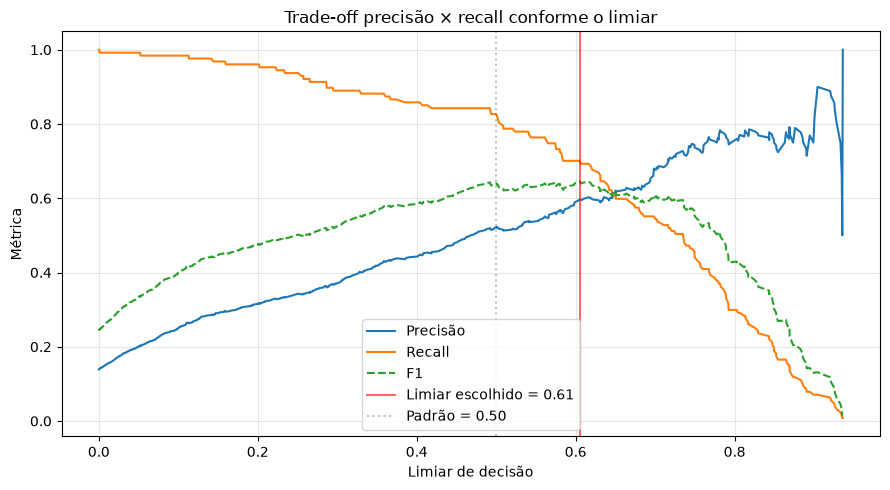

In [7]:
plotar_curva_limiar(info_limiar["curva"], info_limiar["limiar"],
                    caminho="../results/05_limiar_decisao.png")
plt.show()

### Por que o limiar ótimo ficou **acima** de 0,5?

Contraintuitivo à primeira vista: com classe rara, a intuição sugere baixar o corte
para capturar mais positivos.

A explicação é que `class_weight="balanced"` **já fez esse trabalho** durante o treino,
inflando o peso da classe minoritária e deslocando as probabilidades para cima. O
modelo já estava otimista; o limiar de 0,61 corrige o excesso. São dois mecanismos
atuando sobre o mesmo desequilíbrio.

Na região à direita do gráfico, a curva de precisão fica serrilhada: ali pouquíssimas
amostras são classificadas como positivas, e cada acerto move a métrica violentamente.
Não se otimiza nessa faixa — é ruído, não sinal.

## 6. Avaliação final no conjunto de teste

O teste é usado **uma única vez**, com modelo e limiar já decididos. Métricas da classe
"Alta", que é a rara e a que interessa ao negócio:

- **Precisão** — dos vinhos classificados como bons, quantos realmente eram? Responde
  "posso confiar quando o modelo diz que é bom?".
- **Recall** — dos vinhos realmente bons, quantos o modelo encontrou?
- **F1** — média harmônica das duas; usada quando há desbalanceamento.
- **ROC-AUC** — probabilidade de o modelo dar nota maior a um vinho bom que a um comum.
  Não depende do limiar, pois mede ordenação e não ponto de corte.

In [8]:
resultados = pd.DataFrame([
    {"modelo": "Regressão Logística",
     **avaliar_modelo(modelos["Regressão Logística"], X_test, y_test)},
    {"modelo": "Random Forest (limiar 0.50)",
     **avaliar_modelo(rf, X_test, y_test)},
    {"modelo": "Random Forest (limiar otimizado)",
     **avaliar_modelo(rf, X_test, y_test, info_limiar["limiar"])},
])

resultados.to_csv("../results/metricas_comparacao.csv", index=False)
resultados

NotFittedError: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [ ]:
predicoes = {
    "Regressão Logística": modelos["Regressão Logística"].predict(X_test),
    "Random Forest (limiar otimizado)": prever_com_limiar(rf, X_test, info_limiar["limiar"]),
}

plotar_matrizes_confusao(predicoes, y_test, caminho="../results/03_matrizes_confusao.png")
plt.show()

### Interpretação dos resultados

**O contraste que define o projeto:** a acurácia do modelo final é ~88,6%, contra 86,1%
do baseline trivial. Um ganho de 2,5 pontos. Apresentar apenas a acurácia faria o
trabalho parecer inútil — mas o **ROC-AUC de 0,892** revela que o modelo aprendeu
bastante: dados um vinho bom e um comum ao acaso, ele ordena corretamente em 89% dos
casos. A acurácia simplesmente não consegue mostrar isso, porque é dominada pela
classe majoritária.

**O ganho do ajuste de limiar** (0,50 → 0,61): os falsos positivos caíram de 22 para
**16, sem perder um único vinho bom** — o recall permaneceu em 0,688 e o F1 subiu de
0,579 para 0,629. Na prática: 6 lotes deixaram de ser engarrafados como premium
indevidamente, a custo zero.

A validação cruzada previu F1 de 0,645 e o teste entregou 0,629 — diferença de 1,6
ponto. O limiar **generalizou**, não foi ajuste ao acaso.

**Os dois tipos de erro não custam o mesmo.** Um falso positivo (vinho comum vendido
como premium) gera decepção do cliente e dano à marca. Um falso negativo (vinho bom
vendido na linha básica) gera perda de margem, mas nenhuma reclamação. É por isso que
privilegiar precisão foi a escolha correta neste contexto.

**Limitação a registrar:** o conjunto de teste tem apenas 32 vinhos de alta qualidade.
Cada acerto ou erro desloca o recall em ~3 pontos percentuais. As diferenças têm
componente de variabilidade amostral.

## 7. Quais variáveis determinam a qualidade

Dois métodos complementares. A **importância da Random Forest** mostra *quanto* cada
variável contribui, mas não a direção. O **odds ratio da Regressão Logística** mostra
*para que lado* ela empurra: valor 2,0 significa que aumentar a variável em um
desvio-padrão dobra a chance de classificação como alta qualidade.

A convergência entre os dois é o que dá confiança à interpretação.

In [ ]:
import numpy as np

fig, importancias = plotar_importancia(rf, X.columns,
                                       caminho="../results/04_importancia_variaveis.png")
plt.show()

coef = pd.Series(modelos["Regressão Logística"].named_steps["clf"].coef_[0], index=X.columns)
odds = np.exp(coef).sort_values(ascending=False)

pd.DataFrame({"importancia_rf": importancias, "odds_ratio_logistica": odds.round(3)})

### Leitura dos fatores

**Álcool domina** — 21,7% da importância e odds ratio 2,69: cada desvio-padrão a mais
quase **triplica** a chance de alta qualidade. Mas atenção à interpretação causal: o
álcool é *marcador* de uva madura, colhida no ponto certo, com fruta concentrada. Não
é causa. Adicionar álcool a um vinho ruim não o torna bom.

**Acidez volátil é o maior inimigo** — odds ratio 0,627: cada desvio-padrão a mais
**reduz em 37%** a chance de alta qualidade. Aqui a relação *é* causal: acidez volátil
é essencialmente ácido acético (vinagre), um defeito de fermentação.

**Sulfatos (1,98) e ácido cítrico (1,63)** completam o quarteto principal. Juntas, as
quatro variáveis respondem por **61% da importância** do modelo.

**Açúcar residual é irrelevante** (4,6%), confirmando os boxplots da EDA — o que
desmonta a intuição leiga de que vinho doce ou seco define qualidade.

**Cuidado metodológico:** a importância por redução de impureza favorece variáveis
contínuas com muitos valores distintos e dilui a importância entre variáveis
correlacionadas entre si. A EDA mostrou multicolinearidade relevante (`fixed acidity`
× `pH` = −0,69; `free` × `total sulfur dioxide` = 0,66). O topo do ranking é confiável;
a ordenação exata das posições intermediárias, menos.

## 8. Implicações para a produção

**Controlar a acidez volátil é a alavanca de maior retorno.** É o único dos quatro
fatores principais sob controle direto do enólogo durante a fermentação — higiene do
tanque, controle de oxigênio, prevenção de contaminação por bactérias acéticas.

**Definir o ponto de colheita pelo açúcar da uva** maximiza o potencial alcoólico, que
é o preditor mais forte.

**Triagem automatizada de lotes.** Com AUC de 0,89, o modelo ordena bem. A aplicação
correta é *priorizar* quais lotes seguem para avaliação sensorial humana, não substituir
o especialista. As 11 variáveis já são medidas por rotina no laboratório, então o custo
marginal da implementação é praticamente zero.

## 9. Persistência do modelo

O modelo é salvo junto com **o limiar** e **a ordem das features**. As três coisas
andam juntas por necessidade: sem o limiar, quem carregar o modelo usaria 0,5 e
perderia o ganho do ajuste; sem a ordem das features, um formulário que monte o vetor
em ordem diferente produziria previsões erradas **sem lançar erro algum**.

In [ ]:
salvar_modelo(rf, info_limiar["limiar"], X.columns, "../models/random_forest.pkl")
print("Modelo salvo em ../models/random_forest.pkl")